In [1]:
import os
import numpy as npx
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

## UMAP

In [2]:
path = r"E:\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv\masked_ratio_means-wide.csv"
df = pd.read_csv(path)
col_groups = {
    "ORR": ["Redox"],
    "CAR" :[
        "Positive_Ion_3",
        "Positive_Ion_4",
        "Positive_Ion_5"
    ],
    "CL" : [
        "Negative_Ion_33", #1447.965 CL 72:8 (-H),
        "Negative_Ion_34",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "Negative_Ion_1",
        "Negative_Ion_3",
        "Positive_Ion_7",
    ],
    "PL (Sat)" :[
        "Positive_Ion_11",
        "Negative_Ion_7",
        "Negative_Ion_18",
    ],
    "PL (MUFA)":[
        "Positive_Ion_14",
        "Positive_Ion_18",
        "Negative_Ion_5",
        "Negative_Ion_17",
        "Negative_Ion_21",   
    ] ,
    "PL (AA)":[
        "Negative_Ion_8",
        "Negative_Ion_10",
        "Negative_Ion_11",
        "Negative_Ion_12",
        "Negative_Ion_14",
        "Negative_Ion_19",
        "Negative_Ion_23",
        "Positive_Ion_15",
        "Positive_Ion_16",
        "Positive_Ion_21",
    ],
    "PL (DHA)":[
        "Negative_Ion_9",
        "Negative_Ion_15",
    ],
    "PL (PUFA)":[
        "Positive_Ion_19",
        "Positive_Ion_20",
        "Negative_Ion_26",
        "Negative_Ion_30",
        "Negative_Ion_31",
    ],
    "Lipid Unsat.": ["Lipid_Unsaturation"],
    "SM":[
        "Positive_Ion_9",
        "Positive_Ion_13",
        "Positive_Ion_22",
        "Positive_Ion_23",
        "Positive_Ion_24",
        "Positive_Ion_25",
        "Negative_Ion_4"
    ],
            "SHexCer" : [
        "Negative_Ion_22",
        "Negative_Ion_24",
        "Negative_Ion_27",
        "Negative_Ion_28",
        "Negative_Ion_29",
        "Negative_Ion_32"
    ],

        "Fib. Collagen": [
        'Collagen',
        "Collagen_Thickness",
        "Collagen_Coherence"
    ],

}
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])


In [8]:
df['Group_ID']

0         Inner Cortex
1          CM Boundary
2         Outer Stripe
3         Inner Stripe
4         Outer Cortex
              ...     
147404    Outer Stripe
147405    Outer Stripe
147406    Outer Stripe
147407    Outer Stripe
147408    Outer Stripe
Name: Group_ID, Length: 147409, dtype: category
Categories (5, object): ['Outer Cortex' < 'Inner Cortex' < 'CM Boundary' < 'Outer Stripe' < 'Inner Stripe']

In [6]:
path = r"E:\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv\masked_ratio_means-wide.csv"
df = pd.read_csv(path)
col_groups = {
    "ORR": ["Redox"],
    "CAR" :[
        "Positive_Ion_3",
        "Positive_Ion_4",
        "Positive_Ion_5"
    ],
    "CL" : [
        "Negative_Ion_33", #1447.965 CL 72:8 (-H),
        "Negative_Ion_34",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "Negative_Ion_1",
        "Negative_Ion_3",
        "Positive_Ion_7",
    ],
    "PL (Sat)" :[
        "Positive_Ion_11",
        "Negative_Ion_7",
        "Negative_Ion_18",
    ],
    "PL (MUFA)":[
        "Positive_Ion_14",
        "Positive_Ion_18",
        "Negative_Ion_5",
        "Negative_Ion_17",
        "Negative_Ion_21",   
    ] ,
    "PL (AA)":[
        "Negative_Ion_8",
        "Negative_Ion_10",
        "Negative_Ion_11",
        "Negative_Ion_12",
        "Negative_Ion_14",
        "Negative_Ion_19",
        "Negative_Ion_23",
        "Positive_Ion_15",
        "Positive_Ion_16",
        "Positive_Ion_21",
    ],
    "PL (DHA)":[
        "Negative_Ion_9",
        "Negative_Ion_15",
    ],
    "PL (PUFA)":[
        "Positive_Ion_19",
        "Positive_Ion_20",
        "Negative_Ion_26",
        "Negative_Ion_30",
        "Negative_Ion_31",
    ],
    "Lipid Unsat.": ["Lipid_Unsaturation"],
    "SM":[
        "Positive_Ion_9",
        "Positive_Ion_13",
        "Positive_Ion_22",
        "Positive_Ion_23",
        "Positive_Ion_24",
        "Positive_Ion_25",
        "Negative_Ion_4"
    ],
            "SHexCer" : [
        "Negative_Ion_22",
        "Negative_Ion_24",
        "Negative_Ion_27",
        "Negative_Ion_28",
        "Negative_Ion_29",
        "Negative_Ion_32"
    ],

        "Fib. Collagen": [
        'Collagen',
        "Collagen_Thickness",
        "Collagen_Coherence"
    ],

}
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# df = df[df['Source_ID']=='S21']

for new_col, source_cols in col_groups.items():
    df[new_col] = df[source_cols].mean(axis=1)

unit_order = [
      "Cluster1",
      "Cluster2",
      "Cluster4",
      "Cluster5",
      "Cluster6",
      "Cluster7",
      "Cluster9",
      "Cluster10",
      "Cluster11",
      "Cluster13",
      "Cluster15",
      "Cluster16",
      "Cluster17",
      "Cluster18",
      "Cluster19",
      "Cluster20",
      "Cluster21",
      "Cluster23",
      "Cluster24",
      "Cluster25",
      "Cluster26"
    ]
# group_order = ['OC', 'IC', 'CM', 'OS', "IS"]

group_order = ['C1', 'C2', 'C3', 'CM', 'M']

group_map ={
    'C1': 'Outer Cortex',
    'C2': 'Inner Cortex',
    'C3': 'CM Boundary',
    'CM': 'Outer Stripe',
    'M': 'Inner Stripe'
}

df['Unit'] = pd.Categorical(df['Unit'], categories=unit_order, ordered=True)
df['Group_ID'] = pd.Categorical(df['Group_ID'], categories=group_order, ordered=True)
for i, val_col in enumerate(df.columns[6:]):
    df[val_col] = df[val_col].fillna(df.groupby(['Group_ID', 'Unit'])[val_col].transform('median'))

df['Group_ID'] = df['Group_ID'].map(group_map)

C:\Users\jvill\AppData\Local\Temp\ipykernel_21172\2688427448.py:126: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[val_col] = df[val_col].fillna(df.groupby(['Group_ID', 'Unit'])[val_col].transform('median'))


In [7]:
import umap 

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().set_output(transform="pandas")
umap_df = df.copy()
umap_df[df.columns[6:-13]] = scaler.fit_transform(df[df.columns[6:-13]])
umap_df = umap_df.dropna()
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
embedding = reducer.fit_transform(umap_df[df.columns[6:-13]])

umap_df['umap_1'] = embedding[:, 0]
umap_df['umap_2'] = embedding[:, 1]
        

c:\Users\jvill\anaconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\jvill\anaconda3\envs\hsi_machine_learning\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


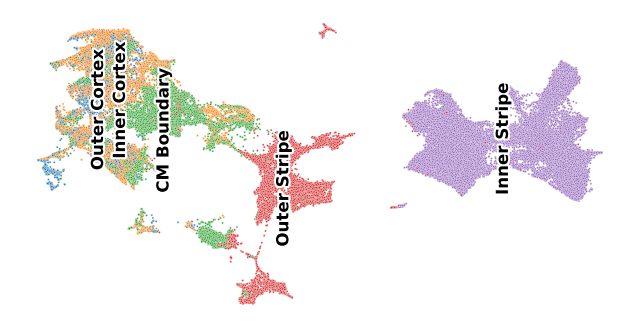

In [103]:
import matplotlib.patheffects as pe
import numpy as np
fig, ax = plt.subplots(figsize=(8, 4))

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster9": "#840a62",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster13": "#0a3b84",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }


umap_df = umap_df.sample(frac=1, random_state=42)
sns.scatterplot(
    data=umap_df,
    x='umap_1', y='umap_2',
    hue='Group_ID',
    # palette=hue_colors,
    # hue_order=hue_order_display,
    alpha=0.9,
    edgecolor='w',
    linewidth=0.2,
    s=2,
    ax=ax
)
embeddings = umap_df[["umap_1", "umap_2"]].values
labels = umap_df["Group_ID"].values
unique_labels = umap_df["Group_ID"].unique()

# 5. Place clean, bold labels at each cluster's median centroid
for label in unique_labels:
    mask = labels == label
    # Using median for both coordinates yields a better geometric center
    centroid_x = np.mean(embeddings[mask, 0])
    centroid_y = np.mean(embeddings[mask, 1])

    ax.text(
        centroid_x,
        centroid_y,
        label,
        fontsize=12,  # Adjusted to fit 6x6 figure nicely
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        rotation=90,
        path_effects=[pe.withStroke(linewidth=3, foreground="white")],
        zorder=100,
    )
# Formatting axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# Remove the default legend (since we have text labels on centroids)
legend = ax.get_legend()
if legend is not None:
    legend.remove()
plt.savefig(os.path.join(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks", "r-UMAP.png"), dpi=300, transparent=True)

## Region Gradients

In [ ]:
path = r"E:\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv\masked_ratio_means-wide.csv"
df = pd.read_csv(path)
col_groups = {
    "ORR": ["Redox"],
    "CAR" :[
        "Positive_Ion_3",
        "Positive_Ion_4",
        "Positive_Ion_5"
    ],
    "CL" : [
        "Negative_Ion_33", #1447.965 CL 72:8 (-H),
        "Negative_Ion_34",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "Negative_Ion_1",
        "Negative_Ion_3",
        "Positive_Ion_7",
    ],
    "PL (Sat)" :[
        "Positive_Ion_11",
        "Negative_Ion_7",
        "Negative_Ion_18",
    ],
    "PL (MUFA)":[
        "Positive_Ion_14",
        "Positive_Ion_18",
        "Negative_Ion_5",
        "Negative_Ion_17",
        "Negative_Ion_21",   
    ] ,
    "PL (AA)":[
        "Negative_Ion_8",
        "Negative_Ion_10",
        "Negative_Ion_11",
        "Negative_Ion_12",
        "Negative_Ion_14",
        "Negative_Ion_19",
        "Negative_Ion_23",
        "Positive_Ion_15",
        "Positive_Ion_16",
        "Positive_Ion_21",
    ],
    "PL (DHA)":[
        "Negative_Ion_9",
        "Negative_Ion_15",
    ],
    "PL (PUFA)":[
        "Positive_Ion_19",
        "Positive_Ion_20",
        "Negative_Ion_26",
        "Negative_Ion_30",
        "Negative_Ion_31",
    ],
    "Lipid Unsat.": ["Lipid_Unsaturation"],
    "SM":[
        "Positive_Ion_9",
        "Positive_Ion_13",
        "Positive_Ion_22",
        "Positive_Ion_23",
        "Positive_Ion_24",
        "Positive_Ion_25",
        "Negative_Ion_4"
    ],
            "SHexCer" : [
        "Negative_Ion_22",
        "Negative_Ion_24",
        "Negative_Ion_27",
        "Negative_Ion_28",
        "Negative_Ion_29",
        "Negative_Ion_32"
    ],

        "Fib. Collagen": [
        'Collagen',
        "Collagen_Thickness",
        "Collagen_Coherence"
    ],

}
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

df = df[df['Source_ID']=='S21']

for new_col, source_cols in col_groups.items():
    df[new_col] = df[source_cols].mean(axis=1)

unit_order = [
      "Cluster1",
      "Cluster2",
      "Cluster4",
      "Cluster5",
      "Cluster6",
      "Cluster7",
      "Cluster9",
      "Cluster10",
      "Cluster11",
      "Cluster13",
      "Cluster15",
      "Cluster16",
      "Cluster17",
      "Cluster18",
      "Cluster19",
      "Cluster20",
      "Cluster21",
      "Cluster23",
      "Cluster24",
      "Cluster25",
      "Cluster26"
    ]
# group_order = ['OC', 'IC', 'CM', 'OS', "IS"]

group_order = ['C1', 'C2', 'C3', 'CM', 'M']
df['Unit'] = pd.Categorical(df['Unit'], categories=unit_order, ordered=True)
df['Group_ID'] = pd.Categorical(df['Group_ID'], categories=group_order, ordered=True)

In [ ]:
import numpy as np

group_order = ['C1', 'C2', 'C3', 'CM', 'M']
df['Unit'] = pd.Categorical(df['Unit'], categories=unit_order, ordered=True)
df['Group_ID'] = pd.Categorical(df['Group_ID'], categories=group_order, ordered=True)

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster9": "#840a62",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster13": "#0a3b84",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }

fig, ax = plt.subplots(figsize=(2.25*len(col_groups.keys()), 6), ncols=len(col_groups.keys()), nrows=1, sharey=True)

regions = ['Outer\nCortex', 'Inner\nCortex', 'CM\nBoundary', 'Outer\nStripe', 'Inner\nStripe']
for i, val_col in enumerate(col_groups.keys()):
    item_data_plot = df[['Unit', 'Group_ID', val_col]].replace([np.inf, -np.inf], np.nan).dropna(subset=[val_col]).copy()
    agg_data_plot = item_data_plot.groupby(['Group_ID', 'Unit'])[val_col].agg(['mean', 'count']).reset_index()
    agg_data_plot['unit_total']= agg_data_plot.groupby('Unit')['count'].transform('sum')
    agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
    pivot_df = agg_data_plot.pivot(index='Group_ID', columns='Unit', values='mean')

    z_df = pivot_df.copy().astype(float)
    z_values = z_df.to_numpy(dtype=float)
    z_mean = np.nanmean(z_values)
    z_std = np.nanstd(z_values)
    if np.isnan(z_std) or z_std == 0:
        z_df = z_df - z_mean
    else:
        z_df = (z_df - z_mean) / z_std

    item_abs_max = np.nanmax(np.abs(z_df.to_numpy(dtype=float)))
    if np.isnan(item_abs_max):
        item_abs_max = 0

    inverted_df = z_df.iloc[::-1, ::-1]
    inverted_df.plot(ax=ax[i], kind='barh', xlabel=val_col, width=0.9, color=list(hue_colors.values())[::-1]) 
    # ax[i].set_yticklabels(group_order[::-1],fontsize=14, fontweight='bold')


    ax[i].axvline(0, color='lightgray', linestyle='--')
    ax[i].get_legend().remove() 


    y_ticks = ax[i].get_yticks()

    if i == 0:
        sns.despine(ax=ax[i], top=True, right=True, left=False)
    elif i == len(col_groups.keys()):
        sns.despine(ax=ax[i], top=True, right=False, left=True)
    else:
        sns.despine(ax=ax[i], top=True, right=True, left=True)

    if len(y_ticks) > 1:
        # Calculate the distance between bars
        spacing = y_ticks[1] - y_ticks[0]
        
        # This includes boundary lines below the first bar and above the last bar
        minor_ticks = np.arange(y_ticks[0] - spacing/2, y_ticks[-1] + spacing, spacing)
        ax[i].set_yticks(minor_ticks, minor=True)
        
        # Turn off the major grid (at the ticks) and turn on the minor grid
        ax[i].grid(False, which='major', axis='y')
        ax[i].grid(True, which='minor', axis='y', linestyle='-.', color='gray', linewidth=0.9)
        
    # ax[i].set_xlim(-2, 2)


    ax[i].tick_params(which='both', axis='y', length=0)
    ax[i].tick_params(axis='x', labelsize=14)
    ax[i].set_yticklabels(regions[::-1], fontsize=20, fontweight='bold')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title(val_col.replace(" ",'\n'), y=1.04, va='center', fontsize=18, fontweight='bold')

    # ax[i].xaxis.label.set(fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks\region_gradient_barplot.png",dpi=300, transparent=True)
plt.show()

In [ ]:
df